In [12]:
import pandas as pd 
import numpy as np
import sklearn

In [13]:
data=pd.read_csv("course_lead_scoring_2026.csv")
df=pd.DataFrame(data)

In [14]:
catigorical_columns=['lead_source','industry','employment_status','location']
numerical_columns=['annual_income','lead_score']

for col in catigorical_columns:
    df[col]=df[col].fillna('NA')

for col in numerical_columns:
    df[col]=df[col].fillna(0)    
    

In [15]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [16]:
df_full_train, df_test = sklearn.model_selection.train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = sklearn.model_selection.train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [17]:
y_train = df_train["converted"].to_numpy()
y_val = df_val["converted"].to_numpy()
y_test = df_test["converted"].to_numpy()


X_train = df_train.drop(columns=["converted"])
X_val = df_val.drop(columns=["converted"])
X_test = df_test.drop(columns=["converted"])

In [18]:
numerical_val=['annual_income','lead_score','number_of_courses_viewed','interaction_count']

In [19]:
from sklearn import metrics
scores={}
for value in numerical_val:
    auc = metrics.roc_auc_score(y_train, df_train[value])

    if auc < 0.5:
        auc = metrics.roc_auc_score(y_train, -df_train[value])
    scores[col] = round(auc, 3)
    
scores    

{'lead_score': 0.765}

training the model and computing the auc

In [20]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[catigorical_columns + numerical_val].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [21]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [ ]:
val_dict = df_val[catigorical_columns + numerical_val].to_dict(orient='records')
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]
auc = metrics.roc_auc_score(y_val, y_pred)

round(auc,3)

0.732

Computing precision and recall then plotting them to find the intersection

In [39]:
df_pred = pd.DataFrame()
thresholds = np.arange(0.0, 1.01, 0.01)
results = []

for t in thresholds:
    convert_decision = (y_pred >= t).astype(int)

    fp = ((convert_decision == 1) & (y_val == 0)).sum()
    tp = ((convert_decision == 1) & (y_val == 1)).sum()
    fn = ((convert_decision == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    F1=2*((precision*recall)/(precision+recall)) if (precision+recall)>0 else 0

    results.append({
        'thresholds': t,
        'precision': precision,
        'recall': recall,
        'f1' : F1
    })

df_pred = pd.DataFrame(results)

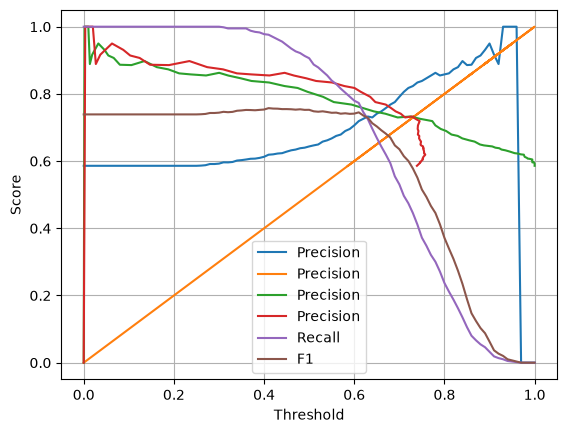

In [42]:
import matplotlib.pyplot as plt

plt.plot(df_pred, df_pred.precision, label='Precision')
plt.plot(df_pred.thresholds, df_pred.recall, label='Recall')
plt.plot(df_pred.thresholds, df_pred.f1, label='F1')


plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

#0.63

In [53]:
from sklearn.model_selection import KFold
from sklearn import metrics
import numpy as np
C=[0.000001, 0.001, 1]
kf = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for (train_idx, val_idx), c in zip(kf.split(df_full_train), C):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].to_numpy()
    y_val = df_val['converted'].to_numpy()

    X_train = df_train.drop(columns=['converted'])
    X_val = df_val.drop(columns=['converted'])

    X_train = X_train.to_dict(orient='records')
    X_val = X_val.to_dict(orient='records')

    X_train = dv.fit_transform(X_train)
    X_val = dv.transform(X_val)
    
    model=LogisticRegression(solver='liblinear', C=c, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]

    auc = metrics.roc_auc_score(y_val, y_pred)

    results.append(np.mean(round(auc, 3)))
    results.append(c)
    
results    



[np.float64(0.594), 1e-06, np.float64(0.748), 0.001, np.float64(0.736), 1]